# Marking edges

Imported geometry often has defects that are invisible at full scale: a step of a thousandth, or an outline that
stops just short of its start. `px.Plot` marks such edges at their midpoints, and it marks any edges you choose in
the same way. Three options do this:

- `mark_edges_smaller=d` marks every edge shorter than d;
- `mark_free_edges=True` marks every edge with an end that no other edge shares;
- `highlight` marks the edges given, as ids, selected edges or faces, or edge indices.

In [1]:
import planex as px

## An imported outline with defects

The example is an outline read as a polyline, with two defects: a step of 0.001 that should not be there, and an end
that does not reach the start. `px.FromPolyline` makes a wire of lines through the points. The step is the only edge
shorter than 1, and the first and the last edge each end in nothing.

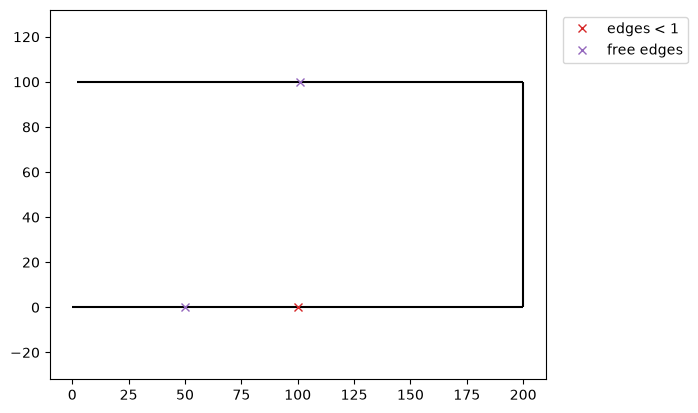

In [2]:
outline = px.FromPolyline([(0, 0), (100, 0), (100, 1e-3), (200, 1e-3), (200, 100), (2, 100)])
outline.Plot(mark_edges_smaller=1, mark_free_edges=True);

## Chosen edges

The example marks the edges of the outline whose centers lie above y = 50, selected with `edges[px.y > 50]`:

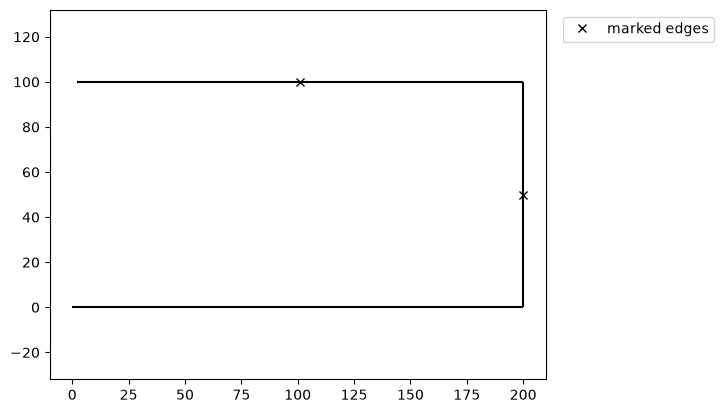

In [3]:
outline.Plot(highlight=outline.edges[px.y > 50]);

## Colors from the edges

With `line_col="property"`, each edge is drawn in its own color, `col`. The example is the flow channel from
[Names and colors](../basics/properties.md), with the inlet in blue and the outlet in orange:

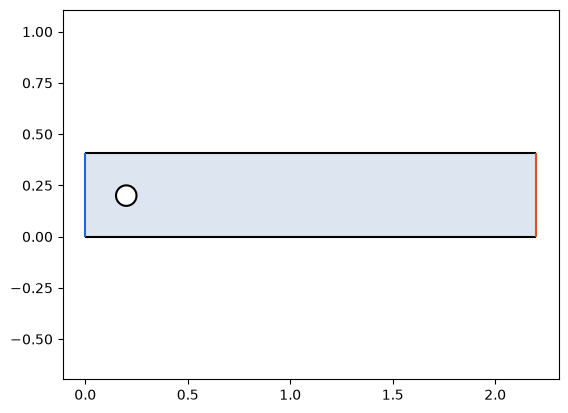

In [4]:
sketch = px.QuickSketch().Line(2.2, name="wall").Line(0, 0.41, name="outlet", col=(0.9, 0.3, 0.1))
channel = sketch.Line(-2.2, 0, name="wall").Close(name="inlet", col=(0.1, 0.4, 0.9)).Face()
fluid = channel - px.Circle((0.2, 0.2), 0.05).Face()
fluid.Plot(line_col="property");

Sketches have plots of their own, with their constraint states, signs and ids. See [Sketch plots](sketches.md) for
details.